# Thực hành 1 — Xây dựng Training Loop
**Lê Sơn Trường**. Nguồn: slide trang 26 và script mẫu trong `ma_nguon_goc/`.
Giữ nguyên 5 epoch, 6000/1000 mẫu, batch64, MLP 784 → 256 → 10, ReLU và Adam.
Chỉ thay learning rate: **0.01, 0.001, 0.0001** theo yêu cầu của slide.
Dữ liệu thật, pixel /255 giống ToTensor; validation lấy từ test theo mã mẫu.
Không có tập test độc lập sau khi dùng validation để so sánh.

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
candidates = [cwd, cwd / "Buoi3", *[p / "Buoi3" for p in cwd.parents]]
BASE = next((p for p in candidates if (p / "yeu_cau_thuc_hanh.md").is_file()), None)
if BASE is None:
    raise FileNotFoundError("Mở notebook từ repository DeepL hoặc thư mục Buoi3.")
sys.path.insert(0, str(BASE))
# Tránh dùng nhầm common/data của các buổi trước trong kernel đang mở.
for name in ["common", "data", "bai02_class_training_loop"]:
    if name in sys.modules and Path(sys.modules[name].__file__).resolve().parent != BASE:
        del sys.modules[name]
from IPython.display import display, Markdown, Image
import torch
print("Lê Sơn Trường | Thiết bị: CPU | PyTorch:", torch.__version__)


Lê Sơn Trường | Thiết bị: CPU | PyTorch: 2.14.1+cpu


In [2]:
from pathlib import Path
import hashlib
from time import perf_counter

import pandas as pd
import torch
from torch import nn

from common import (BASE, Config, EarlyStopping, build_model, build_optimizer, device,
                    evaluate_details, make_loaders, save_experiment, seed_everything,
                    state_digest, synchronize)
from data import load_subset

CONFIGS = [Config(f"adam_lr_{lr:g}", "adam", lr, 256) for lr in [.01, .001, .0001]]
EPOCHS = 5

## Vòng lặp học và đánh giá
`zero_grad` xóa gradient cũ; forward tạo logits; CE tính loss;
`backward` tính gradient; `step` mới cập nhật trọng số.
`model.eval()` và `torch.no_grad()` được dùng khi đánh giá trong common.py.
`online_train_loss` lấy trung bình có trọng số theo số mẫu trong từng batch.
`train_loss` được đo lại ở cuối epoch để so sánh cùng cách với validation.
Đoạn Early Stopping chỉ bật ở phần nâng cao của bài 2; bài 1 học đủ 5 epoch.

In [3]:
def train_configuration(config, train_set, val_set, batch_size, epochs=5, *, early_stopping=False):
    seed_everything(42)
    dev = device()
    model = build_model(config.hidden).to(dev)
    initial_hash = state_digest(model)
    train_loader, train_eval_loader, val_loader = make_loaders(train_set, val_set, batch_size)
    loss_fn = nn.CrossEntropyLoss()  # Nhận logits, nhãn long; không softmax trước CE.
    optimizer = build_optimizer(model, config)
    stopper = EarlyStopping(patience=2, min_delta=0.0) if early_stopping else None
    parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\n{config.name} | device={dev} | parameters={parameters:,} | "
          f"epochs={epochs} | batch={batch_size} | LR={config.lr:g}", flush=True)
    history, training_seconds, batch_hash = [], 0.0, None
    synchronize(dev)
    start = perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum, seen = 0.0, 0
        synchronize(dev)
        epoch_start = perf_counter()
        for xb, yb in train_loader:
            if batch_hash is None:
                batch_hash = hashlib.sha256(xb.numpy().tobytes() + yb.numpy().tobytes()).hexdigest()
            xb, yb = xb.to(dev), yb.to(dev)
            optimizer.zero_grad()           # 1. Xóa gradient cũ
            logits = model(xb)              # 2. Forward
            loss = loss_fn(logits, yb)       # 3. Tính loss
            loss.backward()                 # 4. Backpropagation
            optimizer.step()                # 5. Cập nhật tham số
            loss_sum += loss.item() * len(yb)
            seen += len(yb)
        synchronize(dev)
        training_seconds += perf_counter() - epoch_start

        # Đánh giá không cập nhật trọng số, không tính gradient.
        train_metrics = evaluate_details(model, train_eval_loader, loss_fn)
        val_metrics = evaluate_details(model, val_loader, loss_fn)
        history.append({"config": config.name, "epoch": epoch, "online_train_loss": loss_sum / seen,
                        "train_loss": train_metrics["loss"], "train_accuracy": train_metrics["accuracy"],
                        "val_loss": val_metrics["loss"], "val_accuracy": val_metrics["accuracy"],
                        "val_macro_f1": val_metrics["macro_f1"]})
        print(f"Epoch {epoch}/{epochs} | train_loss={train_metrics['loss']:.4f} | "
              f"online_train_loss={loss_sum / seen:.4f} | val_loss={val_metrics['loss']:.4f} | "
              f"val_accuracy={val_metrics['accuracy']:.2%}", flush=True)
        if stopper is not None and stopper.step(val_metrics["loss"], model, epoch):
            print(f"Early Stopping ở epoch {epoch}; best epoch={stopper.best_epoch}.", flush=True)
            break
    synchronize(dev)
    total_seconds = perf_counter() - start
    epochs_run = len(history)
    selected_epoch = epochs_run
    if stopper is not None:
        stopper.restore(model)
        selected_epoch = stopper.best_epoch
        train_metrics = evaluate_details(model, train_eval_loader, loss_fn)
        val_metrics = evaluate_details(model, val_loader, loss_fn)
    best_row = min(history, key=lambda row: row["val_loss"])
    summary = {"config": config.name, "optimizer": config.optimizer, "lr": config.lr,
               "momentum": config.momentum, "hidden": config.hidden,
               "epochs_requested": epochs, "epochs_run": epochs_run, "selected_epoch": selected_epoch,
               "early_stopping": early_stopping, "stopped_early": epochs_run < epochs,
               "best_epoch": best_row["epoch"], "best_val_loss": best_row["val_loss"],
               "train_samples": len(train_set), "val_samples": len(val_set), "batch_size": batch_size,
               "train_loss": train_metrics["loss"], "val_loss": val_metrics["loss"],
               "train_accuracy": train_metrics["accuracy"], "val_accuracy": val_metrics["accuracy"],
               "val_macro_f1": val_metrics["macro_f1"], "parameters": parameters,
               "training_seconds": training_seconds, "total_seconds": total_seconds}
    predictions = pd.DataFrame({"config": config.name, "sample_index": range(len(val_set)),
                                "target": val_metrics["targets"], "prediction": val_metrics["predictions"],
                                "confidence": val_metrics["confidences"]})
    checkpoint = {"state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                  "hidden": config.hidden, "selected_epoch": selected_epoch,
                  "config": config.name, "val_loss": val_metrics["loss"]}
    return {"summary": summary, "history": history, "predictions": predictions,
            "checkpoint": checkpoint, "initial_hash": initial_hash, "batch_hash": batch_hash}

## Chạy ba learning rate
Mỗi cấu hình được reset seed42, cùng trọng số ban đầu và cùng thứ tự batch.
Kết quả cơ bản lấy epoch 5; không lấy epoch đẹp nhất để thay kết quả cuối.

In [4]:
def main():
    train_set, val_set = load_subset(6000, 1000)
    runs = [train_configuration(c, train_set, val_set, batch_size=64, epochs=EPOCHS) for c in CONFIGS]
    return save_experiment(runs, BASE / "results" / "bai1_learning_rate", val_set,
                           "Thực hành 1 — So sánh learning rate (Adam, 5 epoch)", CONFIGS)

## Chạy và hiển thị kết quả

**Run All** chạy huấn luyện thực sự, giữ nguyên 5 epoch. Kết quả đã được lưu sẵn dưới đây; chỉ đọc thì không cần chạy lại.

In [5]:
summary, history = main()
display(summary)


adam_lr_0.01 | device=cpu | parameters=203,530 | epochs=5 | batch=64 | LR=0.01
Epoch 1/5 | train_loss=0.5020 | online_train_loss=0.8154 | val_loss=0.5526 | val_accuracy=80.80%
Epoch 2/5 | train_loss=0.4233 | online_train_loss=0.5054 | val_loss=0.5244 | val_accuracy=82.20%
Epoch 3/5 | train_loss=0.4796 | online_train_loss=0.4663 | val_loss=0.6139 | val_accuracy=78.00%
Epoch 4/5 | train_loss=0.4658 | online_train_loss=0.4124 | val_loss=0.5910 | val_accuracy=77.60%
Epoch 5/5 | train_loss=0.3328 | online_train_loss=0.3893 | val_loss=0.4770 | val_accuracy=84.40%

adam_lr_0.001 | device=cpu | parameters=203,530 | epochs=5 | batch=64 | LR=0.001
Epoch 1/5 | train_loss=0.6067 | online_train_loss=0.9039 | val_loss=0.6267 | val_accuracy=78.50%
Epoch 2/5 | train_loss=0.4947 | online_train_loss=0.5611 | val_loss=0.5543 | val_accuracy=80.20%
Epoch 3/5 | train_loss=0.4377 | online_train_loss=0.4957 | val_loss=0.4937 | val_accuracy=83.00%
Epoch 4/5 | train_loss=0.4037 | online_train_loss=0.4633 | val

,config,optimizer,lr,momentum,hidden,epochs_requested,epochs_run,selected_epoch,early_stopping,stopped_early,...,batch_size,train_loss,val_loss,train_accuracy,val_accuracy,val_macro_f1,parameters,training_seconds,total_seconds,device
0,adam_lr_0.01,adam,0.0100,0.0,256,5,5,5,False,False,...,64,0.332783,0.476957,0.877833,0.844,0.847225,203530,0.451098,0.644700,cpu
1,adam_lr_0.001,adam,0.0010,0.0,256,5,5,5,False,False,...,64,0.376086,0.460059,0.872333,0.851,0.854356,203530,0.441948,0.634732,cpu
2,adam_lr_0.0001,adam,0.0001,0.0,256,5,5,5,False,False,...,64,0.658906,0.671038,0.783667,0.765,0.760275,203530,0.458527,0.658666,cpu


# Thực hành 1 — So sánh learning rate (Adam, 5 epoch)

Người làm: **Lê Sơn Trường**.

Fashion-MNIST; train/validation = 6000/1000; MLP 784 → 256 → 10, ReLU; seed42; 5 epoch tối đa. Batch train=64, validation=256; CPU, 2 threads.

Train loss/accuracy trên learning curve được đo lại ở cuối epoch bằng eval, cùng cách với validation. online_train_loss là loss trung bình có trọng số của các batch trong lúc cập nhật; hai đại lượng có thể khác nhau.

| Cấu hình | LR | Momentum | Epoch chạy/chọn | Train loss | Val loss | Val accuracy | Macro-F1 | Giây |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| adam_lr_0.01 | 0.01 | 0 | 5/5 | 0.3328 | 0.4770 | 84.40% | 0.8472 | 0.64 |
| adam_lr_0.001 | 0.001 | 0 | 5/5 | 0.3761 | 0.4601 | 85.10% | 0.8544 | 0.63 |
| adam_lr_0.0001 | 0.0001 | 0 | 5/5 | 0.6589 | 0.6710 | 76.50% | 0.7603 | 0.66 |

## Kết quả sau từng epoch

| Cấu hình | Epoch | Device | Số tham số | Train loss | Val loss | Val accuracy |
|---|---:|---|---:|---:|---:|---:|
| adam_lr_0.01 | 1 | cpu | 203,530 | 0.5020 | 0.5526 | 80.80% |
| adam_lr_0.01 | 2 | cpu | 203,530 | 0.4233 | 0.5244 | 82.20% |
| adam_lr_0.01 | 3 | cpu | 203,530 | 0.4796 | 0.6139 | 78.00% |
| adam_lr_0.01 | 4 | cpu | 203,530 | 0.4658 | 0.5910 | 77.60% |
| adam_lr_0.01 | 5 | cpu | 203,530 | 0.3328 | 0.4770 | 84.40% |
| adam_lr_0.001 | 1 | cpu | 203,530 | 0.6067 | 0.6267 | 78.50% |
| adam_lr_0.001 | 2 | cpu | 203,530 | 0.4947 | 0.5543 | 80.20% |
| adam_lr_0.001 | 3 | cpu | 203,530 | 0.4377 | 0.4937 | 83.00% |
| adam_lr_0.001 | 4 | cpu | 203,530 | 0.4037 | 0.4595 | 83.60% |
| adam_lr_0.001 | 5 | cpu | 203,530 | 0.3761 | 0.4601 | 85.10% |
| adam_lr_0.0001 | 1 | cpu | 203,530 | 1.2677 | 1.2715 | 65.40% |
| adam_lr_0.0001 | 2 | cpu | 203,530 | 0.9265 | 0.9326 | 68.80% |
| adam_lr_0.0001 | 3 | cpu | 203,530 | 0.7883 | 0.7985 | 72.90% |
| adam_lr_0.0001 | 4 | cpu | 203,530 | 0.7105 | 0.7220 | 75.60% |
| adam_lr_0.0001 | 5 | cpu | 203,530 | 0.6589 | 0.6710 | 76.50% |

## Nhận xét từ kết quả chạy

- **adam_lr_0.001** có validation loss thấp nhất: **0.4601**. Accuracy cao nhất thuộc **adam_lr_0.001**: **85.10%**.
- LR=0.01: validation loss epoch 1 → 5 là 0.5526 → 0.4770; accuracy 80.80% → 84.40%.
- LR=0.001: validation loss epoch 1 → 5 là 0.6267 → 0.4601; accuracy 78.50% → 85.10%.
- LR=0.0001: validation loss epoch 1 → 5 là 1.2715 → 0.6710; accuracy 65.40% → 76.50%.
- LR quyết định độ lớn bước cập nhật. LR lớn có thể học nhanh hoặc dao động; LR nhỏ có thể chưa hội tụ sau 5 epoch. Đối chiếu các đường thực đo, không mặc định LR lớn luôn kém hay LR nhỏ luôn tốt.
- Bảng cơ bản lấy **epoch cuối**, không chọn lại epoch có điểm đẹp hơn.
- Tất cả cấu hình trong mỗi bài dùng cùng trọng số khởi tạo và cùng thứ tự mini-batch. Số tham số gồm weight và bias; thời gian gồm huấn luyện và đánh giá mỗi epoch, không gồm đọc dữ liệu, khởi tạo hay vẽ biểu đồ.
- Giữ split của mã gốc: validation lấy từ test chính thức. Sau khi dùng để so sánh LR/optimizer, không xem đây là điểm test độc lập. Chỉ một seed và 5 epoch nên kết luận có phạm vi giới hạn.
- Nếu loss không giảm: kiểm tra chuẩn hóa /255, nhãn long, logits thô cho CE, zero_grad/backward/step và LR. Nếu train tốt nhưng val kém: cân nhắc giảm capacity, regularization hoặc thêm dữ liệu trong thí nghiệm mở rộng có ghi rõ cấu hình.



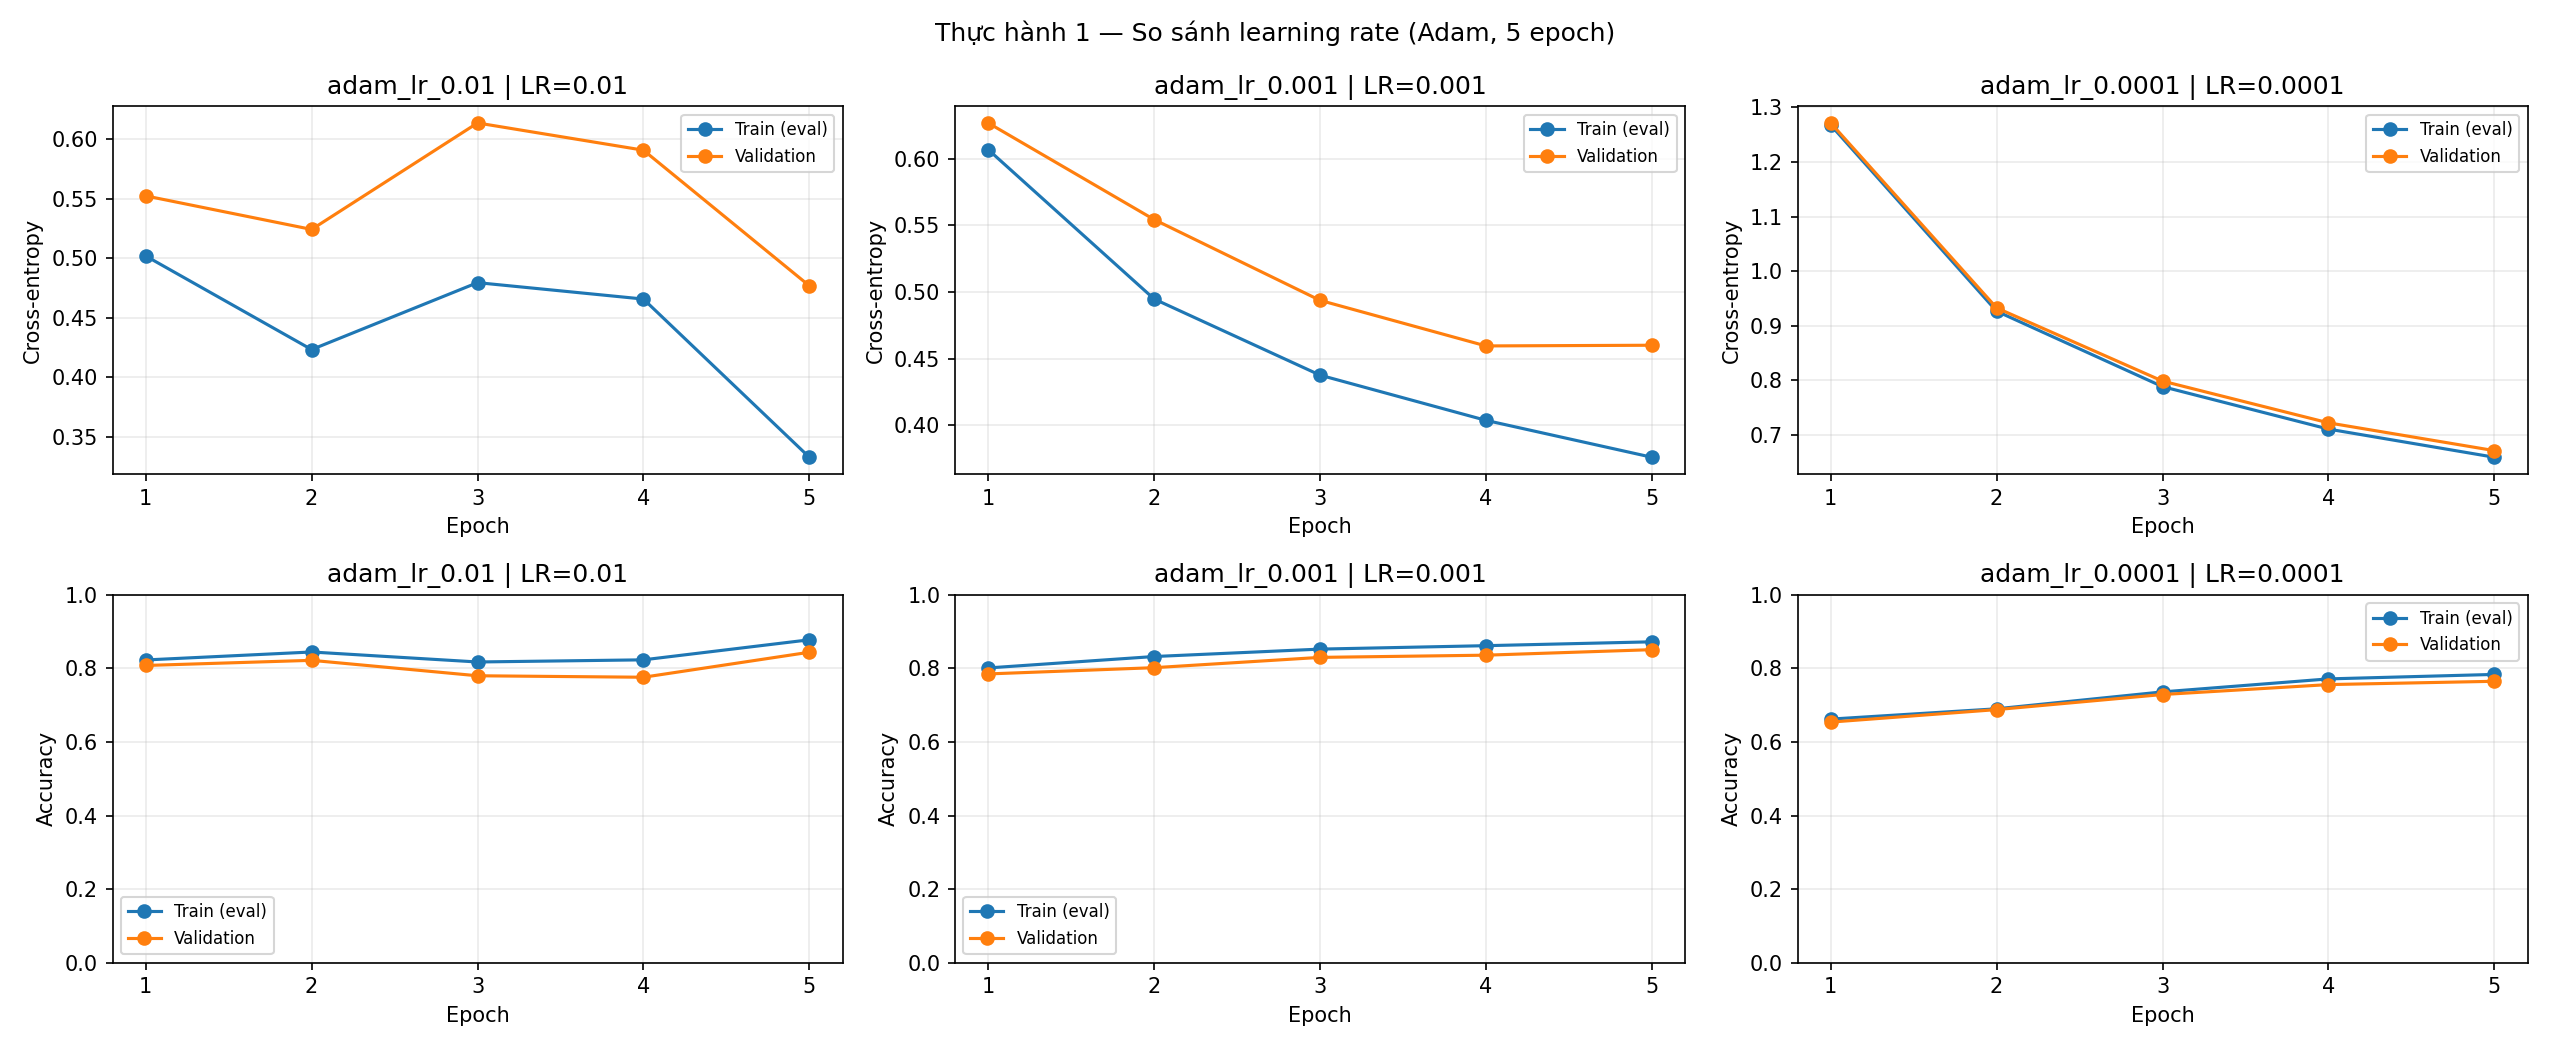

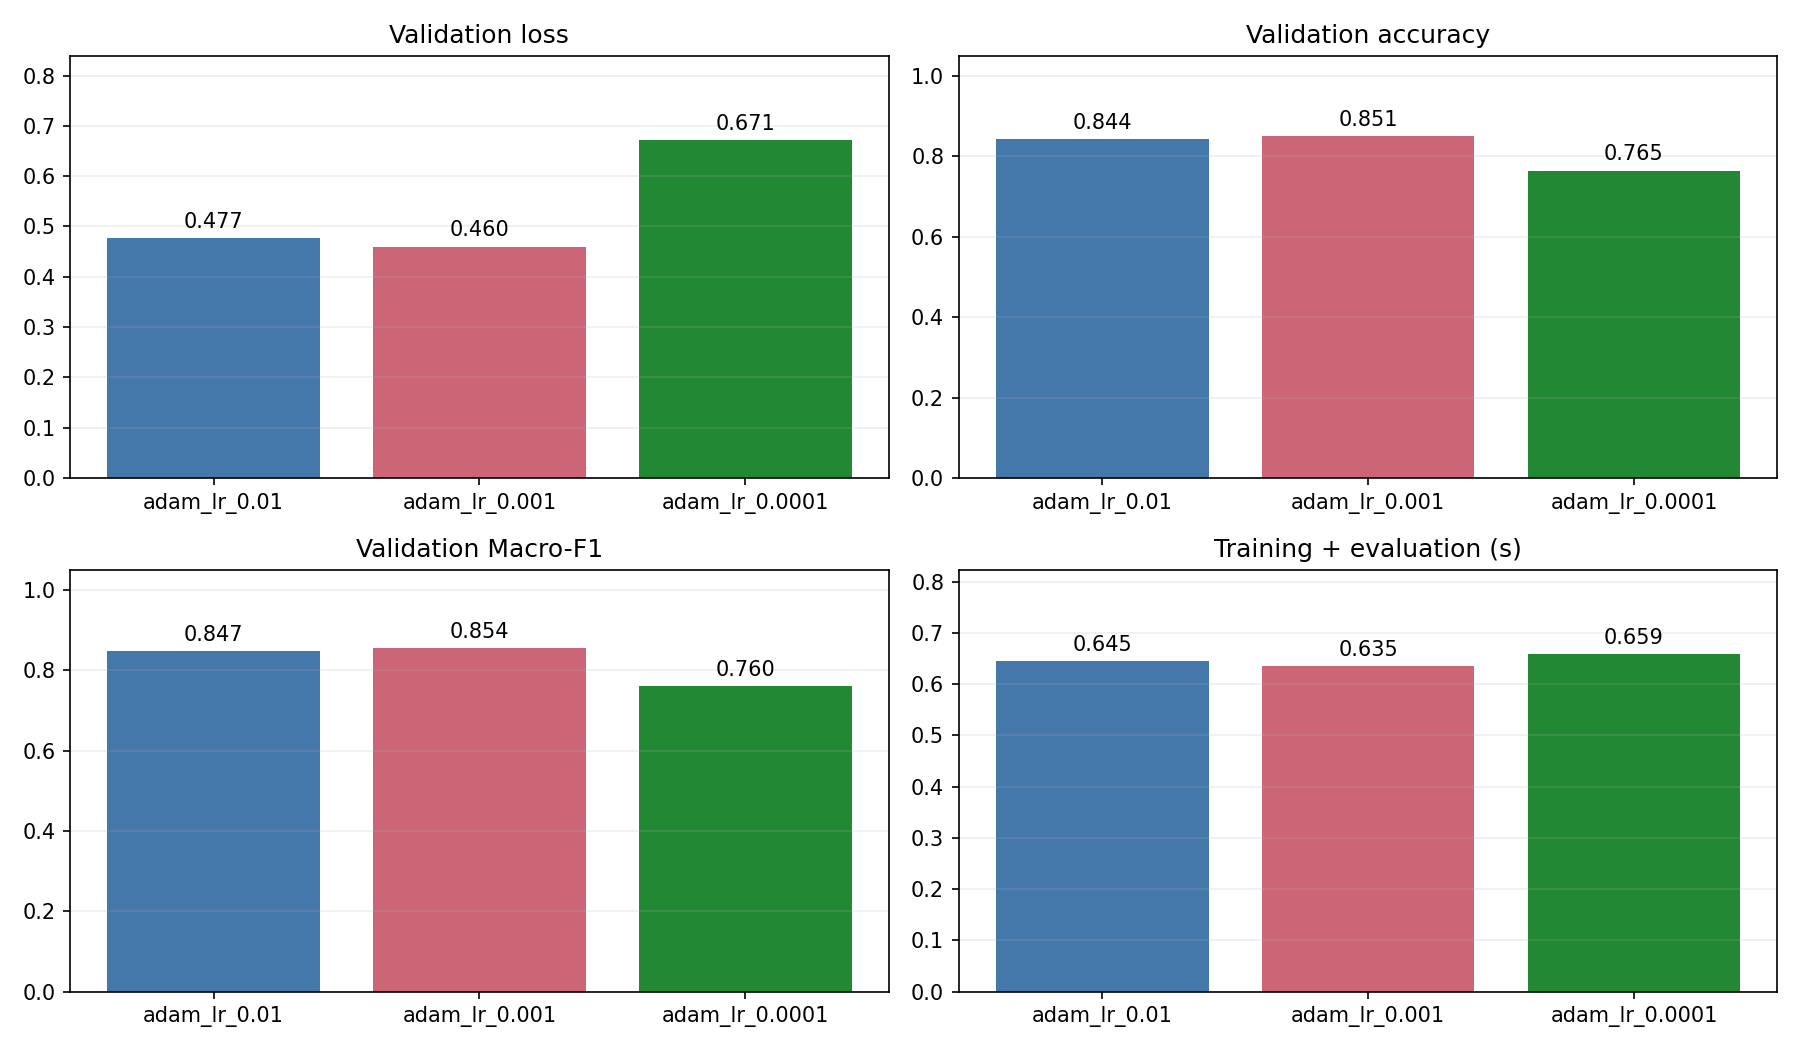

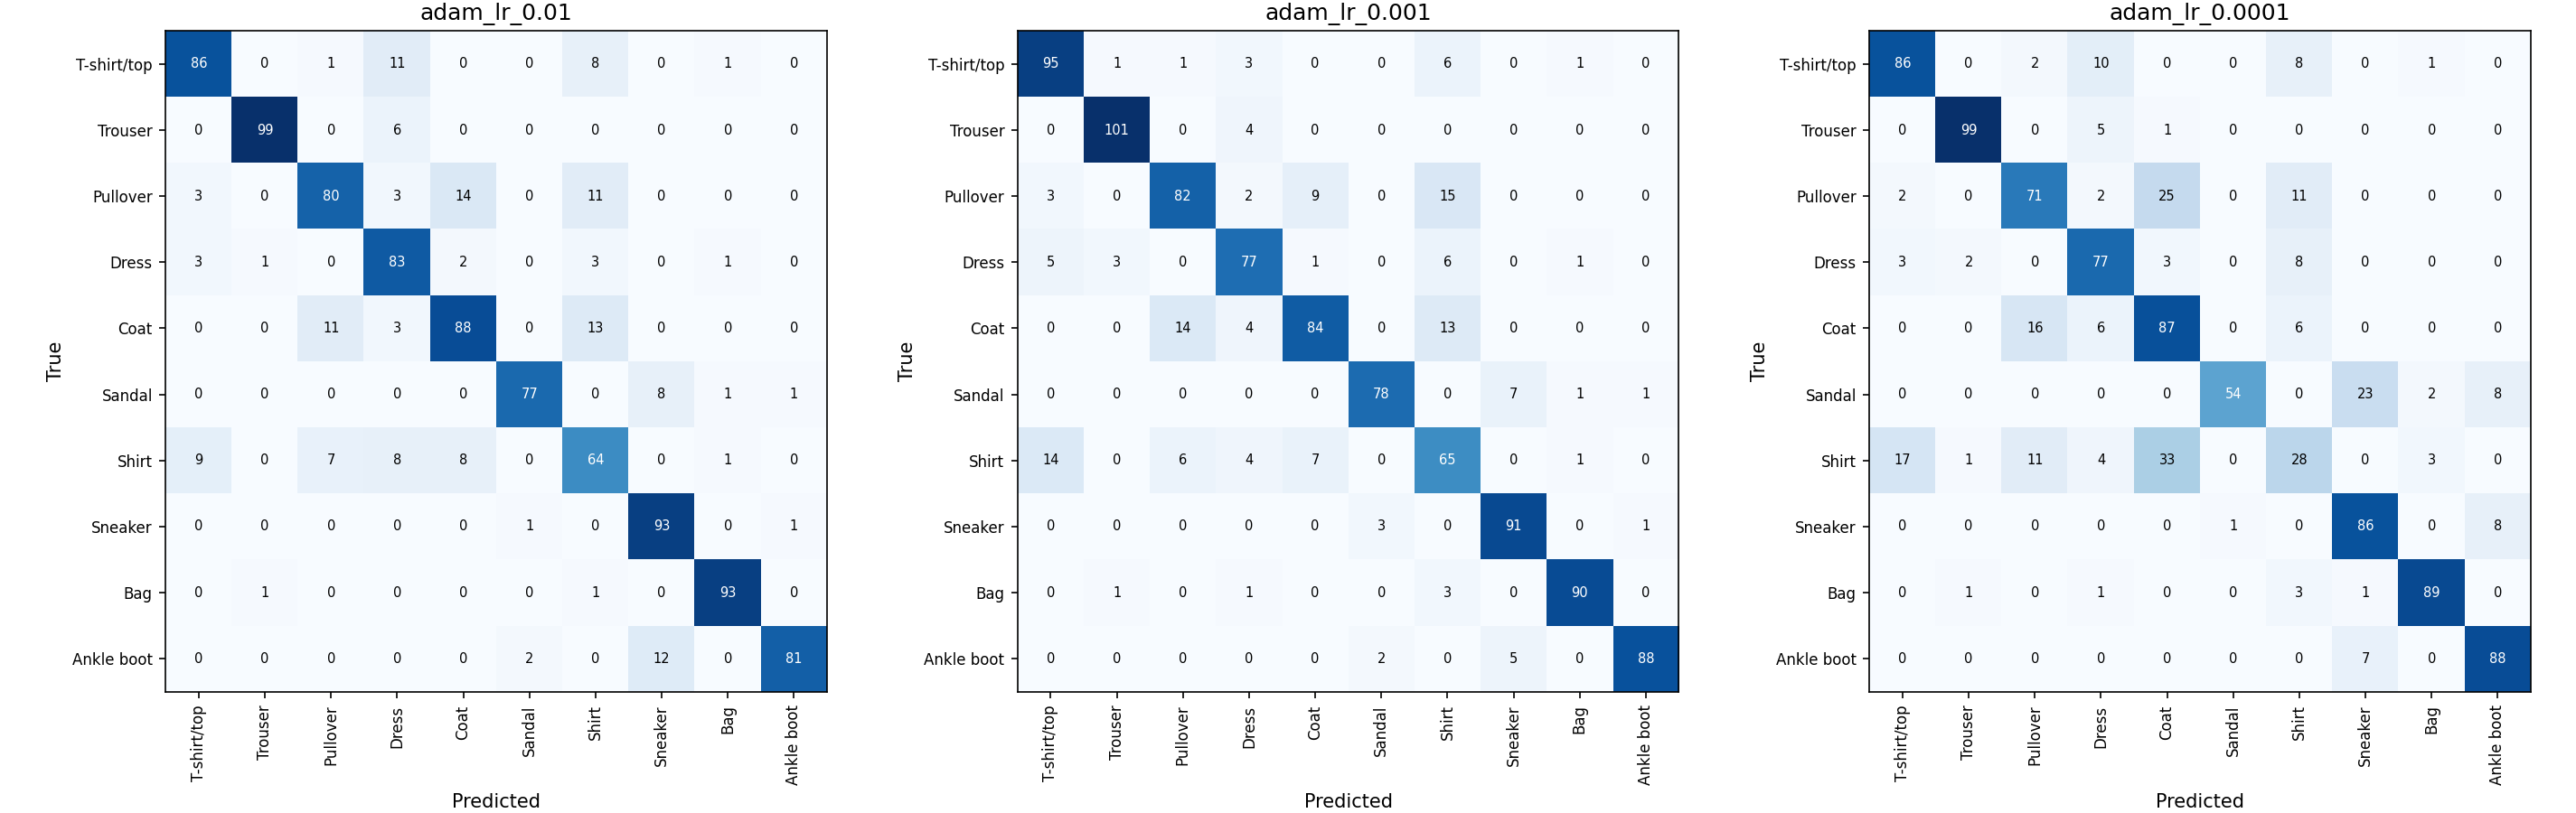

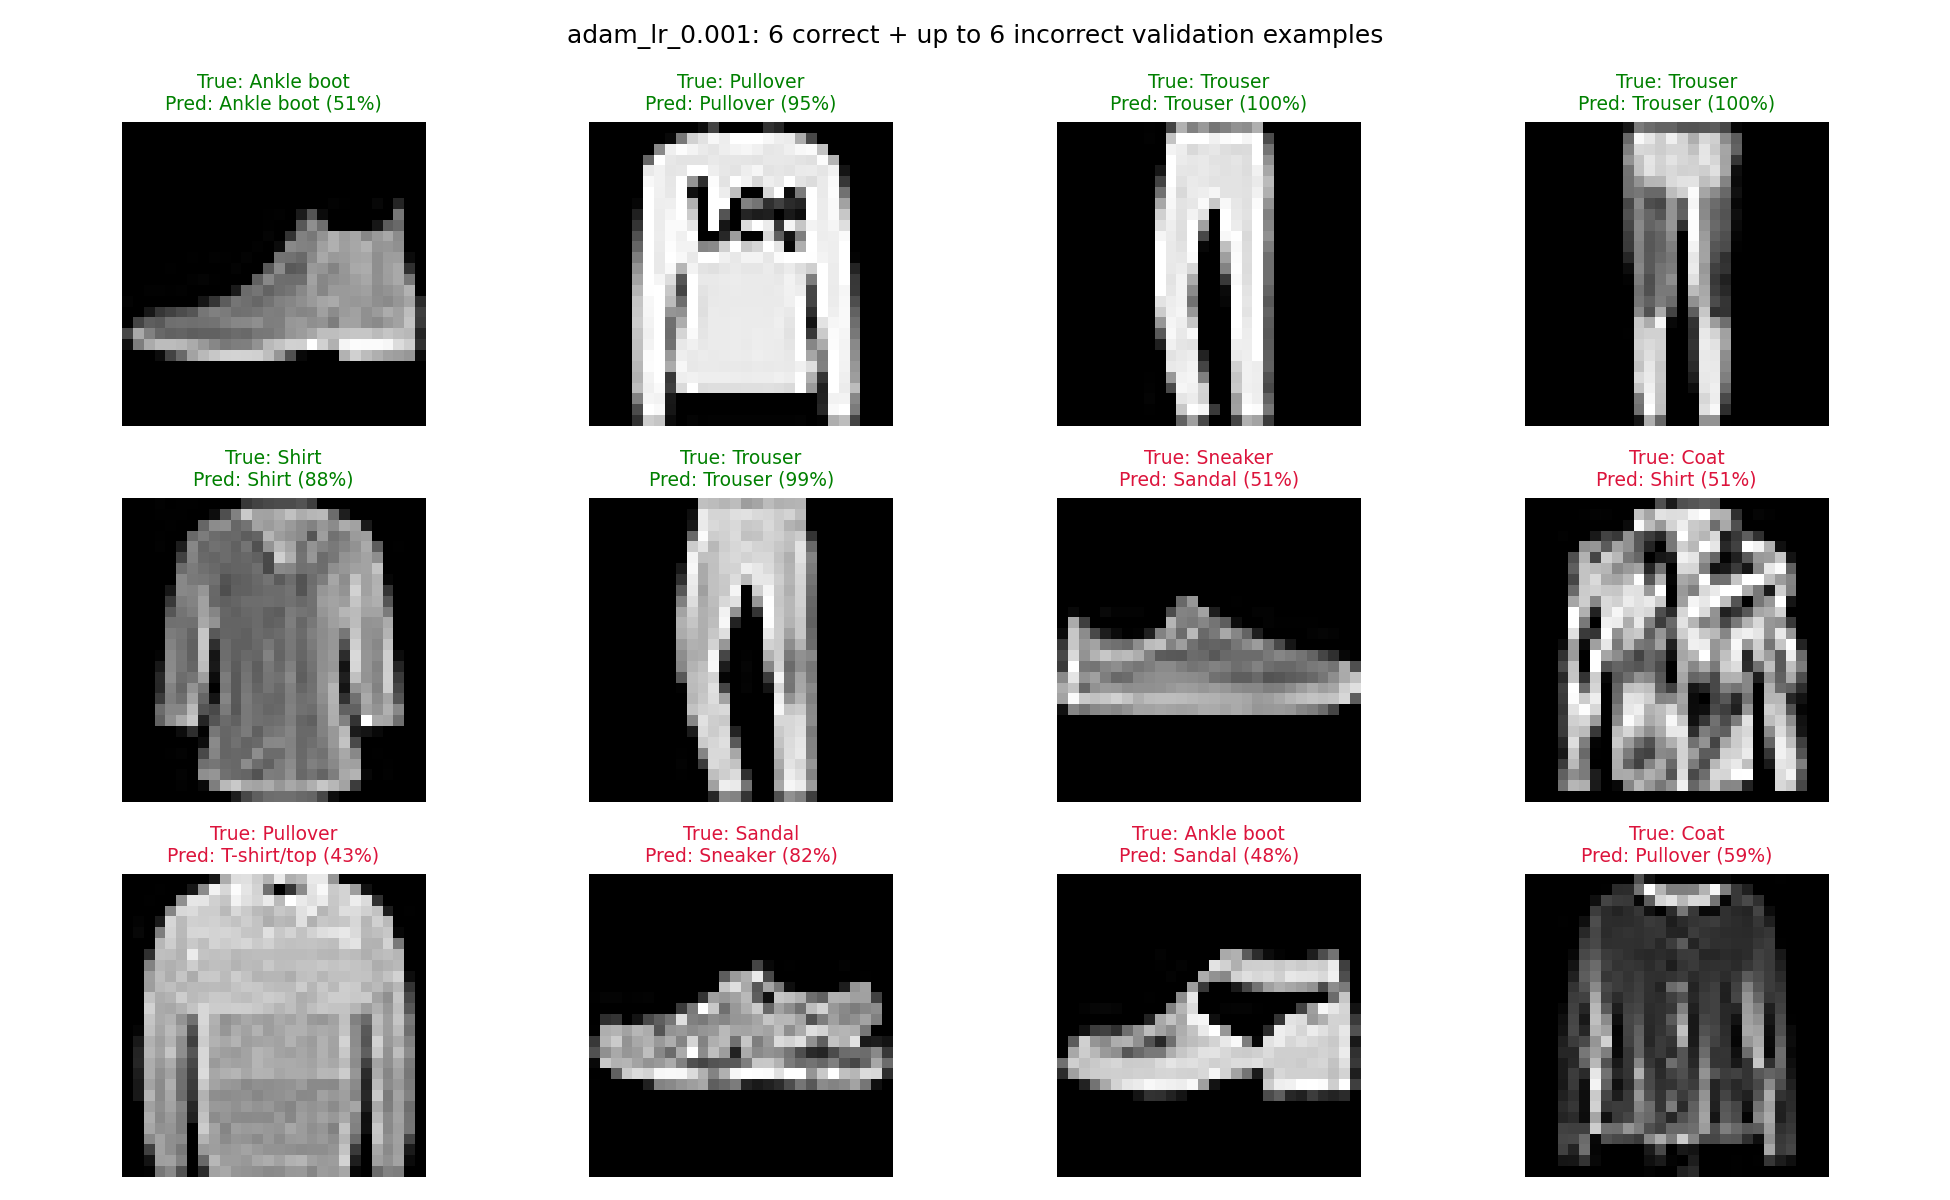

In [6]:
folder = BASE / "results" / "bai1_learning_rate"
display(Markdown((folder / "report.md").read_text(encoding="utf-8").split("![")[0]))
for name in ["learning_curves", "comparison", "confusion_matrices", "prediction_examples"]:
    display(Image(filename=str(folder / f"{name}.png")))